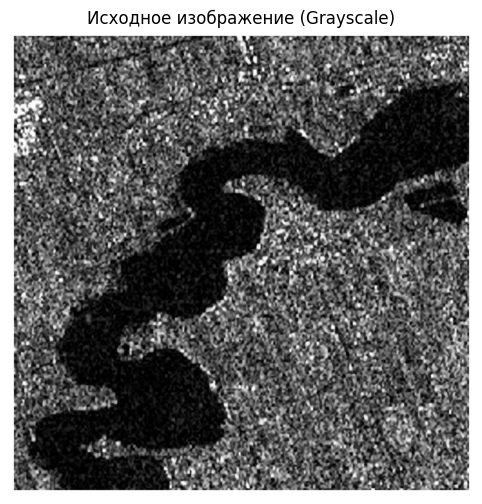

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy

image_filename = 'sar_2.jpg'
image = cv2.imread(image_filename)

if image is None:
    raise FileNotFoundError(f"Файл {image_filename} не найден! Загрузите его в Google Colab.")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение (Grayscale)')
plt.axis('off')
plt.show()

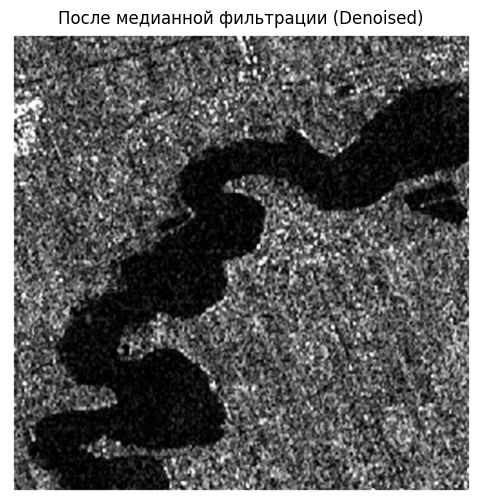

In [4]:
denoised_img = cv2.medianBlur(image_gray, 5)

plt.figure(figsize=(6, 6))
plt.imshow(denoised_img, cmap='gray')
plt.title('После медианной фильтрации (Denoised)')
plt.axis('off')
plt.show()

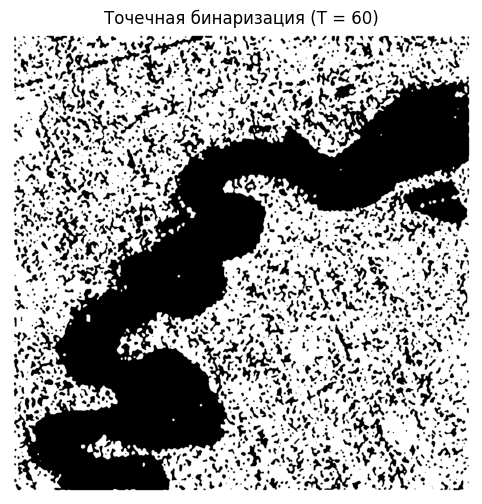

In [5]:
bin_img = copy.deepcopy(denoised_img)
T = 60  # Глобальный порог
bin_img[denoised_img < T] = 0
bin_img[denoised_img >= T] = 255

plt.figure(figsize=(6, 6))
plt.imshow(bin_img, cmap='gray')
plt.title(f'Точечная бинаризация (T = {T})')
plt.axis('off')
plt.show()

Автоматический порог Оцу: 92.0


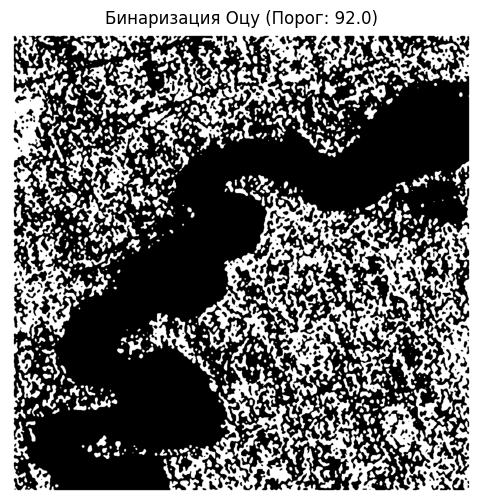

In [6]:
otsu_thresh_val, th_otsu = cv2.threshold(denoised_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Автоматический порог Оцу: {otsu_thresh_val}")

plt.figure(figsize=(6, 6))
plt.imshow(th_otsu, cmap='gray')
plt.title(f'Бинаризация Оцу (Порог: {otsu_thresh_val:.1f})')
plt.axis('off')
plt.show()

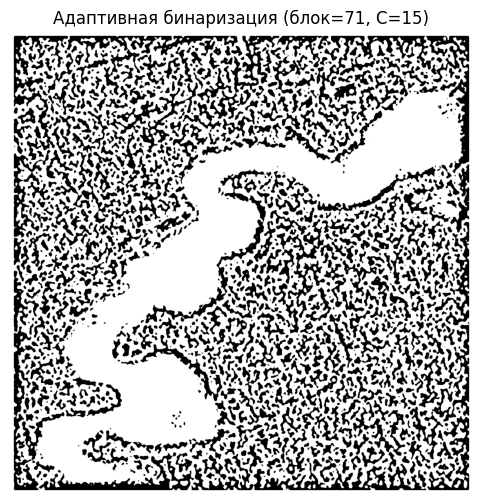

In [7]:
block_size = 71
C = 15
th_adaptive = cv2.adaptiveThreshold(
    denoised_img,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    block_size,
    C
)

plt.figure(figsize=(6, 6))
plt.imshow(th_adaptive, cmap='gray')
plt.title(f'Адаптивная бинаризация (блок={block_size}, C={C})')
plt.axis('off')
plt.show()

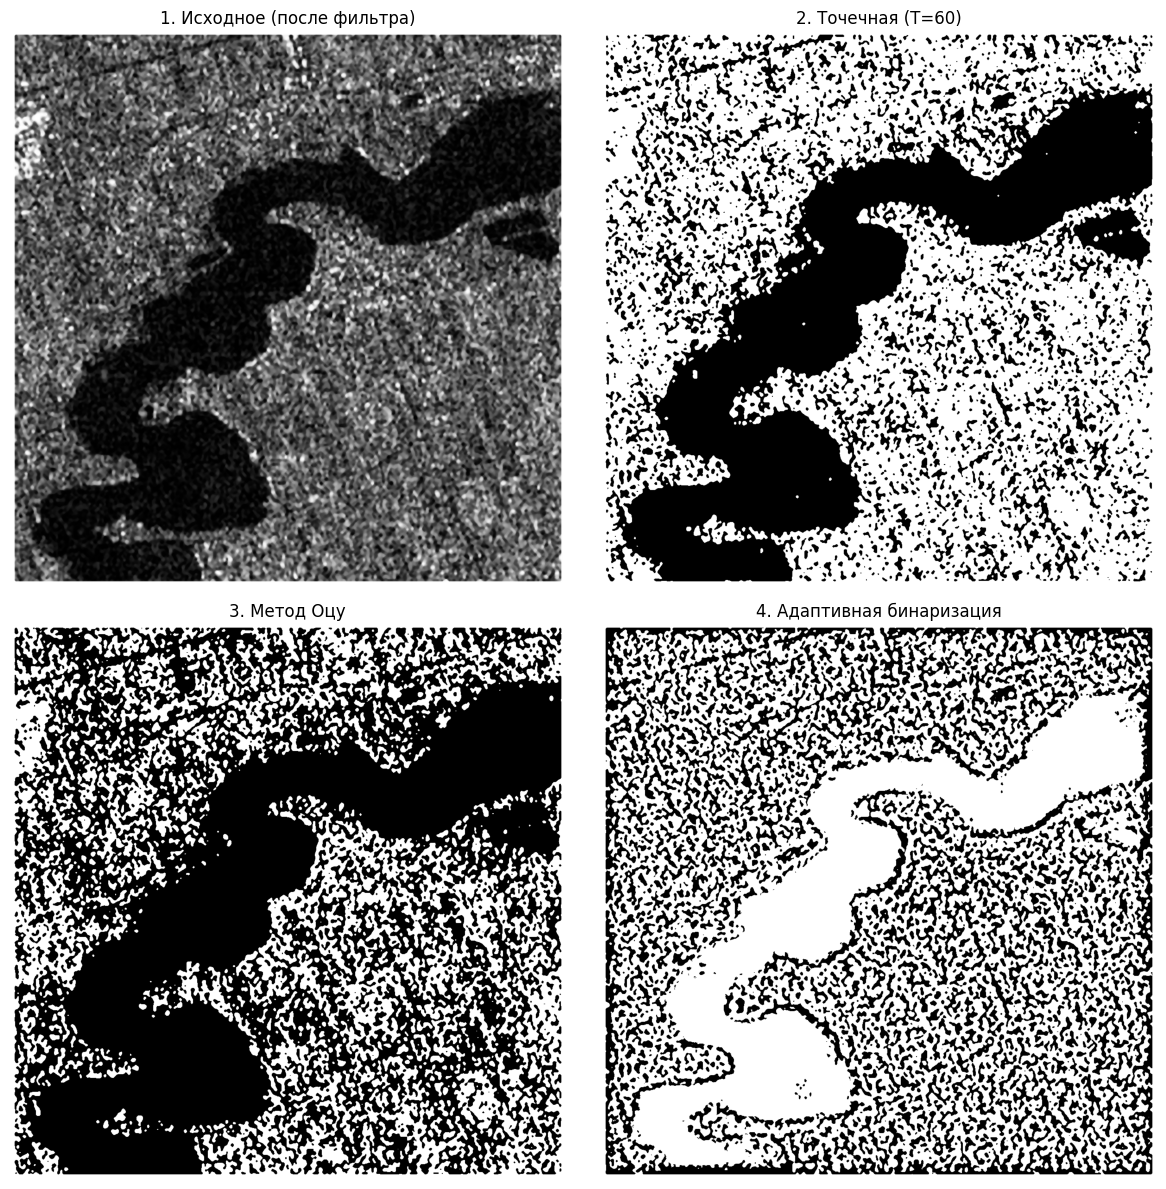

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0, 0].imshow(denoised_img, cmap='gray')
axes[0, 0].set_title('1. Исходное (после фильтра)')
axes[0, 0].axis('off')

axes[0, 1].imshow(bin_img, cmap='gray')
axes[0, 1].set_title(f'2. Точечная (T={T})')
axes[0, 1].axis('off')

axes[1, 0].imshow(th_otsu, cmap='gray')
axes[1, 0].set_title('3. Метод Оцу')
axes[1, 0].axis('off')

axes[1, 1].imshow(th_adaptive, cmap='gray')
axes[1, 1].set_title('4. Адаптивная бинаризация')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()